In [26]:
# 1. imports
import hashlib
import shutil
import json
import keras
import matplotlib.cm as cm
import matplotlib.pyplot as plt
import numpy as np
import os
import gc
import pandas as pd
import tensorflow as tf
from PIL import Image
from keras import layers
from pathlib import Path
from scipy.stats import binomtest
from sklearn import metrics as skm
from sklearn.calibration import calibration_curve
from sklearn.model_selection import train_test_split
from IPython.display import Image as ShowImage, Markdown, display

# Keras' image_dataset_from_directory assigns labels alphabetically: Cat=0, Dog=1.
# The model's sigmoid output is therefore P(Dog).
CLASS_NAMES = ['Cat', 'Dog']
tf.config.list_physical_devices('GPU') # check if GPU is attached

[]

In [27]:
# Settings. Everything lives under one Drive folder:
#   MyDrive/cats-vs-dogs/
#     raw/       downloaded zip + PetImages/ (Cat/, Dog/)
#     data/      cleaned train/val/test split + manifest.csv
#     runs/      one folder per model: model.keras, history.csv, eval/
#     reports/   results table, McNemar test, slice analysis
from google.colab import drive
drive.mount('/content/drive')

PROJECT_DIR = Path('/content/drive/MyDrive/cats-vs-dogs')
RAW_DIR = PROJECT_DIR / 'raw'
DATA_SRC = RAW_DIR / 'PetImages'
DATA_DIR = Path('/content/data')       # fast local disk; rebuilt from the zip after a restart
DATA_ZIP = PROJECT_DIR / 'data.zip'     # one-file backup of the cleaned split on Drive
RUNS_DIR = PROJECT_DIR / 'runs'
REPORTS_DIR = PROJECT_DIR / 'reports'
for d in [RAW_DIR, DATA_DIR, RUNS_DIR, REPORTS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

IMAGE_SIZE = (160, 160)
BATCH_SIZE = 32
CNN_EPOCHS = 40
HEAD_EPOCHS, FINETUNE_EPOCHS = 5, 10
EFFNET_WEIGHTS = 'imagenet'
N_BOOT = 1000
SEED = 1

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [28]:
# 3. Download the Microsoft Kaggle Cats and Dogs dataset (~800 MB)
if not DATA_SRC.exists():
    !wget -q -O "{RAW_DIR}/kagglecatsanddogs_5340.zip" https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip
    !unzip -q "{RAW_DIR}/kagglecatsanddogs_5340.zip" -d "{RAW_DIR}"
print(DATA_SRC, "->", [p.name for p in DATA_SRC.iterdir()])

/content/drive/MyDrive/cats-vs-dogs/raw/PetImages -> ['Dog', 'Cat']


In [29]:
# 4. Images flagged manually
MANUAL_EXCLUDE = {
    "Dog": {5604, 6413, 8736, 8898, 9188, 9517, 10161, 10190, 10237, 10401, 10797, 11186, 11702},
    "Cat": {666, 2939, 3216, 3672, 4688, 4833, 5418, 6215, 7377, 8456, 8470, 10029, 11565, 12272},
}

In [30]:
# 5. check if usable files
def load_clean(path):
  '''Return an RGB PIL image, or None if the file is not a usable image '''
  try:
    # structural check
    with Image.open(path) as img:
      img.verify()
    # full pixel load and conversion
    with Image.open(path) as img:
      img.load()
      return img.convert('RGB')
  except Exception:
    return None


In [31]:
# 6. drop bad files and duplicates
def collect(src, log=print):
  rows = []
  seen = {}
  for class_name in CLASS_NAMES:
    files = sorted((Path(src) / class_name).iterdir())
    n_bad = n_excluded = n_dup = 0
    for f in files:
      if f.stem.isdigit() and int(f.stem) in MANUAL_EXCLUDE[class_name]:
        n_excluded += 1
        continue
      img = load_clean(f)
      if img is None:
        n_bad += 1
        continue
      digest = hashlib.md5(img.tobytes()).hexdigest() # a unique signature for the image content
      if digest in seen:
        n_dup += 1
        continue
      seen[digest] = f
      rows.append({'source': str(f), 'label': class_name, 'width': img.width,
                         'height': img.height, 'md5': digest})
    log(f"{class_name}: {len(files)} files, {n_bad} unreadable, {n_excluded} manually excluded, "
            f"{n_dup} duplicates, {sum(r['label'] == class_name for r in rows)} kept")
  return pd.DataFrame(rows)


In [32]:
# 7. data split 80/10/10
def assign_splits(df, train=0.8, val=0.1, seed=41):
  train_idx, rest_idx = train_test_split(
      df.index, train_size = train, stratify=df['label'], random_state=seed)
  val_idx, test_idx = train_test_split(
      rest_idx, train_size = val / (1 - train), stratify=df.loc[rest_idx,'label'], random_state=seed)
  df = df.copy()
  df.loc[train_idx, 'split'] = 'train'
  df.loc[val_idx, 'split'] = 'val'
  df.loc[test_idx, 'split'] = 'test'
  return df

In [33]:
# 8. write split data
def write_split(df, out):
  out = Path(out)
  paths = []
  for row in df.itertuples():
    dest = out / row.split / row.label / f"{row.label.lower()}_{Path(row.source).stem}.jpg"
    dest.parent.mkdir(parents=True, exist_ok=True)
    load_clean(row.source).save(dest, 'JPEG', quality=95)
    paths.append(str(dest.relative_to(out)))
  df = df.assign(path=paths)
  df.drop(columns=['source']).to_csv(out/'manifest.csv', index=False)
  return df

In [34]:
# 9. tf.data pipeline
def load_split(data_dir, split, image_size=(160,160), batch_size=32, shuffle=False, seed=1):
  ds = tf.keras.utils.image_dataset_from_directory(
      Path(data_dir) / split,
      labels='inferred',
      label_mode='binary',
      class_names=CLASS_NAMES,
      color_mode='rgb',
      image_size=image_size,
      batch_size=None,
      shuffle=False # keep file order so predictions line up with ds.file_paths
  )
  file_paths = ds.file_paths
  ds = ds.map(lambda x, y: (tf.cast(tf.clip_by_value(tf.round(x), 0, 255), tf.uint8), y),
                num_parallel_calls=tf.data.AUTOTUNE).cache() # memory efficient
  if shuffle:
    ds = ds.shuffle(len(file_paths), seed=seed, reshuffle_each_iteration=True)
  ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=tf.data.AUTOTUNE)
  ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
  return ds, file_paths

In [35]:
# 10. load data
def load_all(data_dir, image_size=(160,160), batch_size=32, seed=1):
  train, _ = load_split(data_dir, 'train', image_size, batch_size, shuffle=True, seed=seed)
  val, val_paths = load_split(data_dir, 'val', image_size, batch_size)
  test, test_paths = load_split(data_dir, 'test', image_size, batch_size)
  return train, val, test, {'val': val_paths, 'test': test_paths}

In [36]:
# 11. data augmentation
def augmentation(seed=None):
  # activate only when training = True
  return keras.Sequential([
        layers.RandomFlip('horizontal', seed=seed),
        layers.RandomRotation(0.05, fill_mode='reflect', seed=seed),
        layers.RandomZoom(0.2, 0.2, fill_mode='reflect', seed=seed),
        layers.RandomTranslation(0.1, 0.1, fill_mode='reflect', seed=seed),
        layers.RandomContrast(0.1, seed=seed),
        layers.RandomBrightness(0.2, value_range=(0, 255), seed=seed),
    ], name='augmentation')

In [37]:
#12. updated custom CNN model
def custom_cnn(image_size=(160, 160), n_channel=32, dropout=0.2, l2=1e-4, head="flatten", convs_per_block=1):
  """5 conv blocks + a classifier head.

  head="flatten": the original Flatten -> Dense(512) head (about 6.5M of the 8.1M parameters).
  head="gap": GlobalAveragePooling2D instead, 1.6M parameters in total and not tied to object position.
  convs_per_block=2: two 3x3 convs before each pooling layer.
  """
  reg = keras.regularizers.L2(l2)
  inputs = keras.Input(shape=image_size + (3,))
  x = augmentation()(inputs)
  x = layers.Rescaling(1.0 / 255)(x)
  for i in range(5):
    for _ in range(convs_per_block):
      x = layers.Conv2D(n_channel * 2**i, 3, padding="same", kernel_initializer="he_normal",
                        kernel_regularizer=reg)(x)
      x = layers.BatchNormalization()(x)
      x = layers.ReLU()(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Dropout(dropout)(x)
  if head == "gap":
    x = layers.GlobalAveragePooling2D()(x)
  else:
    x = layers.Flatten()(x)
    x = layers.Dense(512, activation="relu", kernel_regularizer=keras.regularizers.L2(5e-3))(x)
    x = layers.BatchNormalization()(x)
  x = layers.Dropout(dropout)(x)
  outputs = layers.Dense(1, activation="sigmoid")(x)
  return keras.Model(inputs, outputs, name="custom_cnn")

In [38]:
# 13. efficientNet
BACKBONE_NAME = 'backbone'
def efficientnet(image_size=(160,160), weights='imagenet', dropout=0.2):
    """EfficientNetB0 pretrained on ImageNet with a new binary head.
    Keras' EfficientNet does its own input scaling, so it takes [0, 255] pixels directly.
    """
    backbone = keras.applications.EfficientNetB0(
        include_top=False, weights=weights, input_shape=image_size + (3,), pooling='avg')
    backbone.name = BACKBONE_NAME
    backbone.trainable = False
    inputs = keras.Input(shape=image_size + (3,))
    x = augmentation()(inputs)
    x = backbone(x, training=False)  # keep BatchNorm in inference mode, also when fine-tuning
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    return keras.Model(inputs, outputs, name='efficientnet_b0')

In [39]:
# 14. unfreeze for fine-tuning
def unfreeze_top(model, n_layers=40):
  # Unfreeze the last n_layers of the backbone for fine-tuning, leaving BatchNorm frozen
  backbone = model.get_layer(BACKBONE_NAME)
  backbone.trainable = True
  for layer in backbone.layers[:-n_layers]:
    layer.trainable = False
  for layer in backbone.layers:
    if isinstance(layer, layers.BatchNormalization):
      layer.trainable = False

In [40]:
# 15. binary classification performance and probability calibration metrics
def point_metrics(y, p, threshold=0.5):
    """Classification + probability-quality metrics. y: 0=Cat, 1=Dog; p: predicted P(Dog)."""
    pred = (p >= threshold).astype(int)
    return {
        "accuracy": skm.accuracy_score(y, pred),
        "precision_dog": skm.precision_score(y, pred, zero_division=0),
        "recall_dog": skm.recall_score(y, pred, zero_division=0),
        "recall_cat": skm.recall_score(1 - y, 1 - pred, zero_division=0),
        "f1": skm.f1_score(y, pred, zero_division=0),
        "roc_auc": skm.roc_auc_score(y, p) if len(np.unique(y)) == 2 else float("nan"),
        "log_loss": skm.log_loss(y, np.clip(p, 1e-7, 1 - 1e-7), labels=[0, 1]),
        "brier": skm.brier_score_loss(y, p),
        "ece": expected_calibration_error(y, p),
    }

In [41]:
# 16. Percentile Bootstrap Confidence Intervals
def bootstrap_ci(y, p, metric_fn, n_boot=1000, alpha=0.05, seed=0):
  """Percentile bootstrap CI for any metric_fn(y, p) -> float."""
  rng = np.random.default_rng(seed)
  n = len(y)
  stats = []
  for _ in range(n_boot):
    idx = rng.integers(0, n, n)
    if len(np.unique(y[idx])) < 2:
      continue
    stats.append(metric_fn(y[idx], p[idx]))
  lo, hi = np.quantile(stats, [alpha / 2, 1 - alpha / 2])
  return float(lo), float(hi)

In [42]:
# 17. Expected Calibration Error (ECE)
def expected_calibration_error(y, p, n_bins=10):
  '''Average |accuracy - confidence| over equal-width confidence bins, weighted by bin size '''
  conf = np.maximum(p, 1-p)
  correct = ((p >= 0.5).astype(int) == y).astype(float)
  bins = np.linspace(0.5, 1.0, n_bins + 1)
  ece = 0.0
  for lo, hi in zip(bins[:-1], bins[1:]):
    # isolate samples that fall within the current confidence interval
    mask = (conf > lo) & (conf <= hi) if lo > 0.5 else (conf >= lo) & (conf <= hi)
    if mask.any():
      ece += mask.mean() * abs(correct[mask].mean() - conf[mask].mean())
  return float(ece)


In [43]:
# 18. best threshold, pick on validation and apply to test
def best_threshold(y, p):
  candidates = np.linspace(0.05, 0.95, 91)
  accs = [skm.accuracy_score(y, (p >= t).astype(int)) for t in candidates]
  return float(candidates[int(np.argmax(accs))])

In [44]:
# 19 Exact McNemar Test
def mcnemar(y, pred_a, pred_b):
  # Do two classifiers make different errors on the same examples?
  a_right = pred_a == y
  b_right = pred_b == y
  only_a = int(np.sum(a_right & ~b_right))
  only_b = int(np.sum(~a_right & b_right))
  n = only_a + only_b
  p_value = binomtest(only_a, n, 0.5).pvalue if n else 1.0
  return {"only_a_correct": only_a, "only_b_correct": only_b, "p_value": float(p_value)}

In [45]:
# 20. extract the last conv layer
def _last_conv(model):
  convs = [l for l in model.layers if isinstance(l, layers.Conv2D)]
  return convs[-1]

In [46]:
# 21. Grad-CAM (Gradient-weighted Class Activation Mapping)
def gradcam(model, image):
  """Return (heatmap in [0, 1] at the image's size, P(Dog)) for one HxWx3 image in [0, 255].

  Works for both the custom CNN (conv layers in the top-level graph) and the transfer model
  (conv layers inside the nested backbone). The forward pass is replayed layer by layer so the
  tape can see the last conv feature map.
  """
  x = tf.convert_to_tensor(image[None], tf.float32)
  names = {l.name for l in model.layers}
  target = None if BACKBONE_NAME in names else _last_conv(model) # target last layer of my CNN

  with tf.GradientTape() as tape:
    tape.watch(x) # record every op, even through frozen (non-trainable) layers
    h, feats = x, None # feats: feature map
    for layer in model.layers:
      if isinstance(layer, layers.InputLayer):
        continue
      if layer.name == BACKBONE_NAME:
        # EfficientNet's last conv block ends in "top_activation"; use the feature map after it.
        split = keras.Model(layer.inputs, [layer.get_layer("top_activation").output, layer.output])
        feats, h = split(h, training=False)
      else:
        h = layer(h, training=False)
        if layer is target:
          feats = h
    # global avg pooling collapse the spatial dimension, dense layer collapse the channels
    p_dog = h[0, 0] # Extracts the raw final sigmoid probability output
    score = tf.where(p_dog >= 0.5, p_dog, 1.0 - p_dog)  # explain the predicted class, select p_dog if True

  grads = tape.gradient(score, feats)[0]
  # global average pooling
  weights = tf.reduce_mean(grads, axis=(0, 1))
  cam = tf.nn.relu(tf.reduce_sum(feats[0] * weights, axis=-1))
  cam = cam / (tf.reduce_max(cam) + 1e-8)
  cam = tf.image.resize(cam[..., None], image.shape[:2])[..., 0]
  return cam.numpy(), float(p_dog)


In [47]:
# 22. Grad_cam + original
def overlay(image, heatmap, alpha=0.4):
  """Blend a jet-colored heatmap onto an image in [0, 255]; returns uint8."""
  colored = cm.jet(heatmap)[..., :3] * 255
  return np.clip((1 - alpha) * image + alpha * colored, 0, 255).astype(np.uint8)

In [48]:
# 23. df: relative file paths, integer true labels, and predicted probability floats
def predict(model, data_dir, split, image_size, batch_size):
  ds, paths = load_split(data_dir, split, image_size, batch_size)
  y = np.concatenate([yb.numpy().ravel() for _, yb in ds]).astype(int) # flattern with .ravel()
  p = model.predict(ds, verbose=0).ravel()
  rel = [os.path.relpath(f, data_dir) for f in paths]  # same form as manifest.csv: test/Cat/cat_1.jpg
  return pd.DataFrame({"path": rel, "label": y, "p_dog": p})

In [49]:
# 24. structural spatial attributes, and mean brightness
def add_image_features(df, data_dir):
  """Join original resolution from the manifest and compute mean brightness per image."""
  manifest = Path(data_dir) / "manifest.csv"
  if manifest.exists():
    df = df.merge(pd.read_csv(manifest)[["path", "width", "height"]], on="path", how="left")
  else:
    sizes = [Image.open(Path(data_dir) / f).size for f in df["path"]]
    df["width"], df["height"] = zip(*sizes)
  # single-channel grayscale matrix .convert("L") [0, 225]
  df["brightness"] = [np.asarray(Image.open(Path(data_dir) / f).convert("L")).mean() for f in df["path"]]
  df["min_side"] = df[["width", "height"]].min(axis=1)
  df["aspect"] = df["width"] / df["height"]
  return df

In [50]:
# 25. chopping evaluation dataset into distinct metadata segments (slices)
#     calculating statistical accuracy metrics for each group
def slice_table(df, threshold):
    df = df.assign(correct=((df["p_dog"] >= threshold).astype(int) == df["label"]))
    slices = {
        "min_side_px": pd.cut(df["min_side"], [0, 150, 250, 350, 10_000],
                              labels=["<150", "150-250", "250-350", ">350"]),
        "aspect": pd.cut(df["aspect"], [0, 0.8, 1.25, 100], labels=["portrait", "square-ish", "landscape"]),
        "brightness": pd.qcut(df["brightness"], 4, labels=["darkest 25%", "q2", "q3", "brightest 25%"],
                              duplicates="drop"),
        "class": df["label"].map(dict(enumerate(CLASS_NAMES))),
    }
    rows = []
    for name, groups in slices.items():
        for group, sub in df.groupby(groups, observed=True):
            n, acc = len(sub), sub["correct"].mean()
            se = np.sqrt(acc * (1 - acc) / n) if n else np.nan
            rows.append({"slice": name, "group": group, "n": n, "accuracy": acc,
                         "ci95_low": max(0, acc - 1.96 * se), "ci95_high": min(1, acc + 1.96 * se)})
    return pd.DataFrame(rows)

In [51]:
# 26. confusion matrix
def plot_confusion(y, pred, path):
  cm = skm.confusion_matrix(y, pred, labels=[0, 1])
  skm.ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap="Blues", colorbar=False)
  plt.title("Test confusion matrix")
  plt.savefig(path, dpi=150, bbox_inches="tight")
  plt.close()

In [52]:
# 27. ROC diagram
def plot_roc(y, p, path):
  skm.RocCurveDisplay.from_predictions(y, p, name="P(Dog)")
  plt.plot([0, 1], [0, 1], "k--", lw=0.8)
  plt.title("Test ROC curve")
  plt.savefig(path, dpi=150, bbox_inches="tight")
  plt.close()

In [53]:
# 28. Reliability Diagram (Calibration Curve)
def plot_calibration(y, p, path, n_bins=10):
  frac_pos, mean_pred = calibration_curve(y, p, n_bins=n_bins, strategy="quantile")
  plt.figure(figsize=(5, 5))
  plt.plot([0, 1], [0, 1], "k--", lw=0.8, label="perfectly calibrated")
  plt.plot(mean_pred, frac_pos, "o-", label="model")
  plt.xlabel("Predicted P(Dog)")
  plt.ylabel("Observed fraction of dogs")
  plt.title("Reliability diagram (test)")
  plt.legend()
  plt.savefig(path, dpi=150, bbox_inches="tight")
  plt.close()

In [54]:
# 29. most confident mistakes
def plot_errors(model, df, data_dir, image_size, threshold, path, n=12):
    """The model's most confident mistakes, with Grad-CAM overlays."""
    wrong = df[(df["p_dog"] >= threshold).astype(int) != df["label"]].copy()
    wrong["confidence"] = np.maximum(wrong["p_dog"], 1 - wrong["p_dog"])
    wrong = wrong.nlargest(n, "confidence")
    if wrong.empty:
        return
    cols = 4
    rows = int(np.ceil(len(wrong) / cols))
    plt.figure(figsize=(cols * 3, rows * 3.3))
    for i, row in enumerate(wrong.itertuples()):
        img = np.asarray(Image.open(Path(data_dir) / row.path).convert("RGB").resize(image_size), dtype=np.float32)
        heat, p = gradcam(model, img)
        plt.subplot(rows, cols, i + 1)
        plt.imshow(overlay(img, heat))
        plt.title(f"true {CLASS_NAMES[row.label]}, P(Dog)={p:.2f}", fontsize=9)
        plt.axis("off")
    plt.suptitle("Most confident test errors (Grad-CAM)")
    plt.tight_layout()
    plt.savefig(path, dpi=120, bbox_inches="tight")
    plt.close()

In [56]:
# 30. Build the split on local disk once, back it up to Drive as one zip, restore from it after restarts.
if not (DATA_DIR / "manifest.csv").exists():
    if DATA_ZIP.exists():
        shutil.unpack_archive(DATA_ZIP, DATA_DIR)
    else:
        write_split(assign_splits(collect(DATA_SRC), seed=41), DATA_DIR)
        shutil.make_archive(str(DATA_ZIP.with_suffix("")), "zip", DATA_DIR)
pd.read_csv(DATA_DIR / "manifest.csv").groupby(["split", "label"]).size().unstack()

label,Cat,Dog
split,,
test,1247,1248
train,9975,9982
val,1247,1248


In [57]:
# 31. callback and compile
keras.utils.set_random_seed(SEED)
train_ds, val_ds, test_ds, _ = load_all(DATA_DIR, IMAGE_SIZE, BATCH_SIZE, SEED)

def callbacks(out, patience=5):
  return [
    keras.callbacks.ModelCheckpoint(out / "model.keras", monitor="val_loss", save_best_only=True),
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7), # learning rate decay
    keras.callbacks.CSVLogger(out / "history.csv", append=True),
  ]

def compile_model(model, lr):
  model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                metrics=["accuracy", keras.metrics.AUC(name="auc")])

Found 19957 files belonging to 2 classes.
Found 2495 files belonging to 2 classes.
Found 2495 files belonging to 2 classes.


In [68]:
# 32.1 CNN ablation: each step adds one change on top of the step before it.
# Finished steps are skipped, so after a disconnect just rerun this cell.
ABLATION_DIR = RUNS_DIR / "ablation"
BASE = dict(head="flatten", convs_per_block=1, epochs=40, schedule="plateau", patience=5, image_size=(160, 160))
STEPS = [
    ("0_baseline", "original CNN",                  {}),
    ("1_gap",      "+ GlobalAveragePooling2D head", {"head": "gap"}),
    ("2_longer",   "+ 80 epochs, cosine LR",        {"epochs": 80, "schedule": "cosine", "patience": 15}),
    ("3_2conv",    "+ 2 convs per block",           {"convs_per_block": 2}),
    ("4_224px",    "+ 224x224 input",               {"image_size": (224, 224)}),
]

def train_step(cfg, out):
    keras.utils.set_random_seed(SEED)
    train_ds, val_ds, _, _ = load_all(DATA_DIR, cfg["image_size"], BATCH_SIZE, SEED)
    model = custom_cnn(cfg["image_size"], head=cfg["head"], convs_per_block=cfg["convs_per_block"])
    cbs = callbacks(out, cfg["patience"])
    lr = 1e-3
    if cfg["schedule"] == "cosine":
        # Cosine decays the LR to 0 over all epochs, so drop LR-on-plateau (they would fight each other).
        lr = keras.optimizers.schedules.CosineDecay(1e-3, cfg["epochs"] * int(train_ds.cardinality()))
        cbs = [cb for cb in cbs if not isinstance(cb, keras.callbacks.ReduceLROnPlateau)]
    compile_model(model, lr)
    model.fit(train_ds, validation_data=val_ds, epochs=cfg["epochs"], callbacks=cbs)

# Reuse the CNN you already trained (same code, same seed) as step 0 instead of training it again.
base_dir = ABLATION_DIR / "0_baseline"
if (RUNS_DIR / "cnn" / "model.keras").exists() and not (base_dir / "predictions_test.csv").exists():
    base_dir.mkdir(parents=True, exist_ok=True)
    for f in ["model.keras", "history.csv"]:
        shutil.copy(RUNS_DIR / "cnn" / f, base_dir / f)
    best = keras.models.load_model(base_dir / "model.keras")
    predict(best, DATA_DIR, "test", BASE["image_size"], 64).to_csv(base_dir / "predictions_test.csv", index=False)
    (base_dir / "config.json").write_text(json.dumps({**BASE, "label": STEPS[0][1], "params": best.count_params()}))

cfg = dict(BASE)
for name, label, change in STEPS:
    cfg.update(change)
    out = ABLATION_DIR / name
    if (out / "predictions_test.csv").exists():
        print(f"{name}: already done, skipping")
        continue
    keras.backend.clear_session()  # free the previous step's model and cached images before the next one
    gc.collect()
    print(f"{name}: {label}  {cfg}")
    out.mkdir(parents=True, exist_ok=True)
    (out / "history.csv").unlink(missing_ok=True)
    train_step(cfg, out)
    best = keras.models.load_model(out / "model.keras")
    predict(best, DATA_DIR, "test", cfg["image_size"], 64).to_csv(out / "predictions_test.csv", index=False)
    (out / "config.json").write_text(json.dumps({**cfg, "label": label, "params": best.count_params()}))

0_baseline: already done, skipping
1_gap: + GlobalAveragePooling2D head  {'head': 'gap', 'convs_per_block': 1, 'epochs': 40, 'schedule': 'plateau', 'patience': 5, 'image_size': (160, 160)}
Found 19957 files belonging to 2 classes.
Found 2495 files belonging to 2 classes.
Found 2495 files belonging to 2 classes.
Epoch 1/40
624/624 ━━━━━━━━━━━━━━━━━━━━ 69s 89ms/step - accuracy: 0.6096 - auc: 0.6521 - loss: 0.8472 - val_accuracy: 0.6080 - val_auc: 0.7003 - val_loss: 0.8012 - learning_rate: 0.0010
Epoch 2/40
624/624 ━━━━━━━━━━━━━━━━━━━━ 55s 89ms/step - accuracy: 0.6669 - auc: 0.7273 - loss: 0.7205 - val_accuracy: 0.6854 - val_auc: 0.7687 - val_loss: 0.7060 - learning_rate: 0.0010
Epoch 3/40
624/624 ━━━━━━━━━━━━━━━━━━━━ 56s 90ms/step - accuracy: 0.7100 - auc: 0.7792 - loss: 0.6442 - val_accuracy: 0.6517 - val_auc: 0.8234 - val_loss: 0.7234 - learning_rate: 0.0010
Epoch 4/40
624/624 ━━━━━━━━━━━━━━━━━━━━ 57s 91ms/step - accuracy: 0.7458 - auc: 0.8231 - loss: 0.5879 - val_accuracy: 0.7619 - va

In [69]:
# 32.2 Ablation table. Decide whether to keep a change from the val columns; test is for reporting only.
# "fixed / broken": test images this step got right that the previous step got wrong, and the reverse.
rows, prev = [], None
for name, label, _ in STEPS:
    out = ABLATION_DIR / name
    if not (out / "predictions_test.csv").exists():
        continue
    cfg = json.loads((out / "config.json").read_text())
    h = pd.read_csv(out / "history.csv")
    best = h.loc[h["val_loss"].idxmin()]
    test = pd.read_csv(out / "predictions_test.csv").sort_values("path")
    y, p = test["label"].values, test["p_dog"].values
    m = point_metrics(y, p, 0.5)
    lo, hi = bootstrap_ci(y, p, lambda yy, pp: skm.accuracy_score(yy, (pp >= 0.5).astype(int)), N_BOOT)
    row = {"step": label, "params (M)": round(cfg["params"] / 1e6, 2),
           "epochs run": len(h), "best epoch": int(best["epoch"]) + 1,
           "train acc": round(best["accuracy"], 3), "val acc": round(best["val_accuracy"], 3),
           "val loss": round(best["val_loss"], 3),
           "test acc (95% CI)": f"{m['accuracy']:.3f} ({lo:.3f}-{hi:.3f})",
           "dog recall": round(m["recall_dog"], 3), "ECE": round(m["ece"], 3)}
    if prev is not None:
        assert (prev["path"].values == test["path"].values).all()
        t = mcnemar(y, (prev["p_dog"].values >= 0.5).astype(int), (p >= 0.5).astype(int))
        row["fixed / broken vs previous"] = f"{t['only_b_correct']} / {t['only_a_correct']} (p={t['p_value']:.2g})"
    rows.append(row)
    prev = test

ablation = pd.DataFrame(rows)
ablation.to_csv(REPORTS_DIR / "ablation.csv", index=False)
ablation

,step,params (M),epochs run,best epoch,train acc,val acc,val loss,test acc (95% CI),dog recall,ECE,fixed / broken vs previous
0,original CNN,8.13,40,38,0.948,0.939,0.230,0.949 (0.940-0.957),0.921,0.009,NaN
1,+ GlobalAveragePooling2D head,1.57,24,19,0.917,0.929,0.249,0.929 (0.919-0.939),0.925,0.018,48 / 98 (p=4.3e-05)
2,"+ 80 epochs, cosine LR",1.57,80,75,0.969,0.960,0.165,0.968 (0.962-0.975),0.958,0.014,117 / 18 (p=5.7e-19)
3,+ 2 convs per block,4.72,80,66,0.981,0.974,0.133,0.979 (0.974-0.985),0.980,0.006,49 / 22 (p=0.0018)
4,+ 224x224 input,4.72,80,79,0.985,0.976,0.118,0.979 (0.973-0.985),0.981,0.009,29 / 30 (p=1)


In [70]:
# 33. Challenger: EfficientNetB0. Stage 1 trains only the new head on the frozen backbone.
eff_dir = RUNS_DIR / "effnet"; eff_dir.mkdir(parents=True, exist_ok=True)
if not (eff_dir / "model.keras").exists():
  (eff_dir / "history.csv").unlink(missing_ok=True)
  eff = efficientnet(IMAGE_SIZE, weights=EFFNET_WEIGHTS)
  compile_model(eff, 1e-3)
  eff.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS, callbacks=callbacks(eff_dir))

  # Stage 2 fine-tunes the top 40 backbone layers with a small learning rate.
  # The checkpoint is only overwritten if fine-tuning beats stage 1 on validation loss.
  eff.set_weights(keras.models.load_model(eff_dir / "model.keras").get_weights())
  stage1_best = eff.evaluate(val_ds, verbose=0)[0]
  unfreeze_top(eff, 40)
  compile_model(eff, 1e-5)
  cbs = callbacks(eff_dir)
  cbs[0].best = stage1_best
  eff.fit(train_ds, validation_data=val_ds, epochs=FINETUNE_EPOCHS, callbacks=cbs)

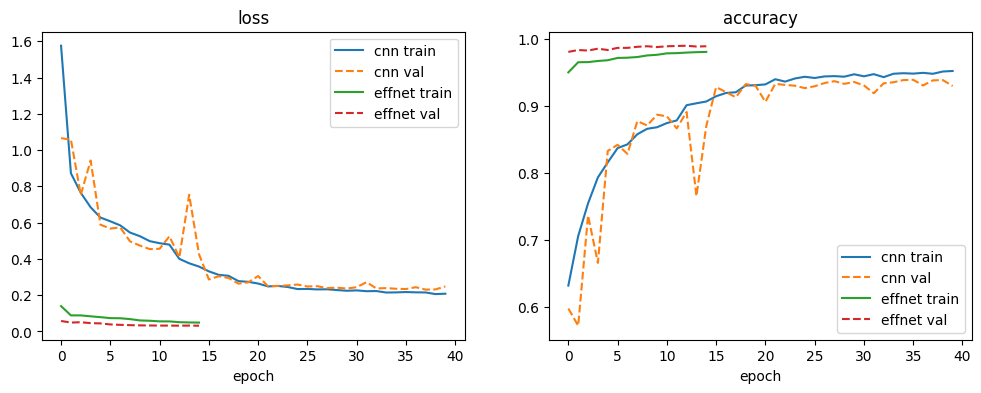

In [71]:
# 34. Learning curves
plt.figure(figsize=(12, 4))
for i, metric in enumerate(["loss", "accuracy"]):
    plt.subplot(1, 2, i + 1)
    for name in ["cnn", "effnet"]:
        h = pd.read_csv(RUNS_DIR / name / "history.csv").reset_index(drop=True)
        plt.plot(h[metric], label=f"{name} train")
        plt.plot(h[f"val_{metric}"], "--", label=f"{name} val")
    plt.xlabel("epoch"); plt.title(metric); plt.legend()
plt.show()

In [61]:
# 35. evaluate run
def evaluate_run(name):
  out = RUNS_DIR / name / "eval"; out.mkdir(exist_ok=True)
  model = keras.models.load_model(RUNS_DIR / name / "model.keras")
  val = predict(model, DATA_DIR, "val", IMAGE_SIZE, 64)
  test = predict(model, DATA_DIR, "test", IMAGE_SIZE, 64)
  threshold = best_threshold(val["label"].values, val["p_dog"].values)
  y, p = test["label"].values, test["p_dog"].values
  accuracy = lambda yy, pp: skm.accuracy_score(yy, (pp >= 0.5).astype(int))
  f1 = lambda yy, pp: skm.f1_score(yy, (pp >= 0.5).astype(int))
  results = {
    "model": name,
    "tuned_threshold_from_val": threshold,
    "at_0.5": point_metrics(y, p, 0.5),
    "at_tuned": point_metrics(y, p, threshold),
    "ci95": {"accuracy": bootstrap_ci(y, p, accuracy, N_BOOT),
              "f1": bootstrap_ci(y, p, f1, N_BOOT),
              "roc_auc": bootstrap_ci(y, p, skm.roc_auc_score, N_BOOT)},
  }
  (out / "metrics.json").write_text(json.dumps(results, indent=2))
  test = add_image_features(test, DATA_DIR)
  test.to_csv(out / "predictions_test.csv", index=False)
  slices = slice_table(test, 0.5)
  slices.to_csv(out / "slices.csv", index=False)
  plot_confusion(y, (p >= 0.5).astype(int), out / "confusion.png")
  plot_roc(y, p, out / "roc.png")
  plot_calibration(y, p, out / "calibration.png")
  plot_errors(model, test, DATA_DIR, IMAGE_SIZE, 0.5, out / "errors_gradcam.png")
  return results, test, slices

results, preds, slices = {}, {}, {}
for key, name in [("cnn", "ablation/3_2conv"), ("effnet", "effnet")]:
  results[key], preds[key], slices[key] = evaluate_run(name)

Found 2495 files belonging to 2 classes.
Found 2495 files belonging to 2 classes.
Found 2495 files belonging to 2 classes.
Found 2495 files belonging to 2 classes.


In [62]:
# 36. Results table with 95% bootstrap CIs
rows = []
for name, r in results.items():
    a, ci = r["at_0.5"], r["ci95"]
    rows.append({"model": name,
                 "test accuracy (95% CI)": f"{a['accuracy']:.3f} ({ci['accuracy'][0]:.3f}-{ci['accuracy'][1]:.3f})",
                 "F1": round(a["f1"], 3), "ROC AUC": round(a["roc_auc"], 4),
                 "cat recall": round(a["recall_cat"], 3), "dog recall": round(a["recall_dog"], 3),
                 "log loss": round(a["log_loss"], 3), "ECE": round(a["ece"], 3)})
results_table = pd.DataFrame(rows)
results_table.to_csv(REPORTS_DIR / "results.csv", index=False)
results_table

,model,test accuracy (95% CI),F1,ROC AUC,cat recall,dog recall,log loss,ECE
0,cnn,0.979 (0.974-0.985),0.979,0.9983,0.978,0.980,0.054,0.006
1,effnet,0.994 (0.990-0.997),0.994,0.9998,0.994,0.994,0.018,0.004


In [63]:
# 37. Is EfficientNet's advantage real? Exact McNemar test on the same test images.
pa, pb = preds["cnn"].sort_values("path"), preds["effnet"].sort_values("path")
assert (pa["path"].values == pb["path"].values).all()
test_result = mcnemar(pa["label"].values, (pa["p_dog"].values >= 0.5).astype(int), (pb["p_dog"].values >= 0.5).astype(int))
(REPORTS_DIR / "mcnemar.json").write_text(json.dumps(test_result, indent=2))
test_result

{'only_a_correct': 11, 'only_b_correct': 47, 'p_value': 2.0315945360449565e-06}

In [64]:
# 38. Where does each model struggle? Accuracy by image resolution, aspect ratio, brightness and class.
slice_report = pd.concat(slices, names=["model"]).reset_index(level=0)
slice_report.to_csv(REPORTS_DIR / "slices.csv", index=False)
slice_report

,model,slice,group,n,accuracy,ci95_low,ci95_high
0,cnn,min_side_px,<150,87,0.954023,0.910014,0.998032
1,cnn,min_side_px,150-250,376,0.976064,0.960614,0.991514
2,cnn,min_side_px,250-350,699,0.979971,0.969585,0.990357
3,cnn,min_side_px,>350,1333,0.981245,0.973963,0.988528
4,cnn,aspect,portrait,403,0.990074,0.980396,0.999753
5,cnn,aspect,square-ish,785,0.982166,0.972907,0.991424
6,cnn,aspect,landscape,1307,0.973986,0.965357,0.982616
7,cnn,brightness,darkest 25%,624,0.975962,0.963944,0.987980
8,cnn,brightness,q2,624,0.979167,0.967960,0.990373
9,cnn,brightness,q3,623,0.977528,0.965890,0.989167


### ablation/3_2conv

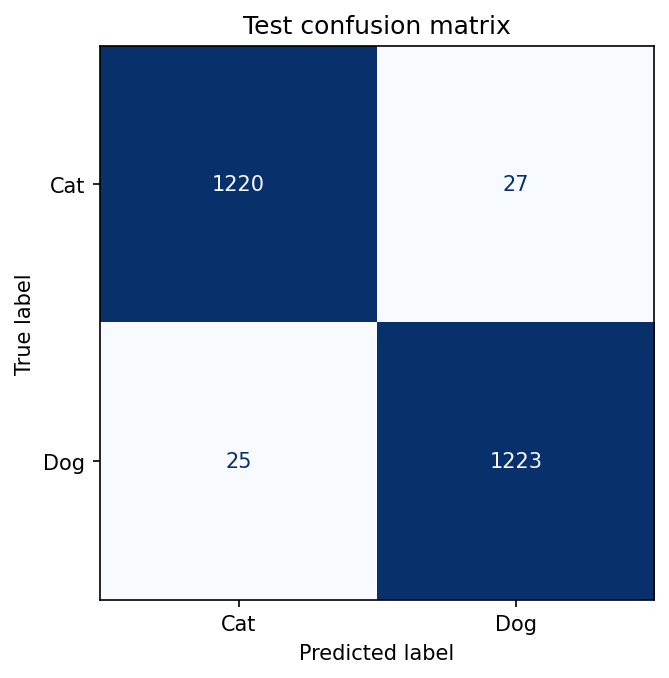

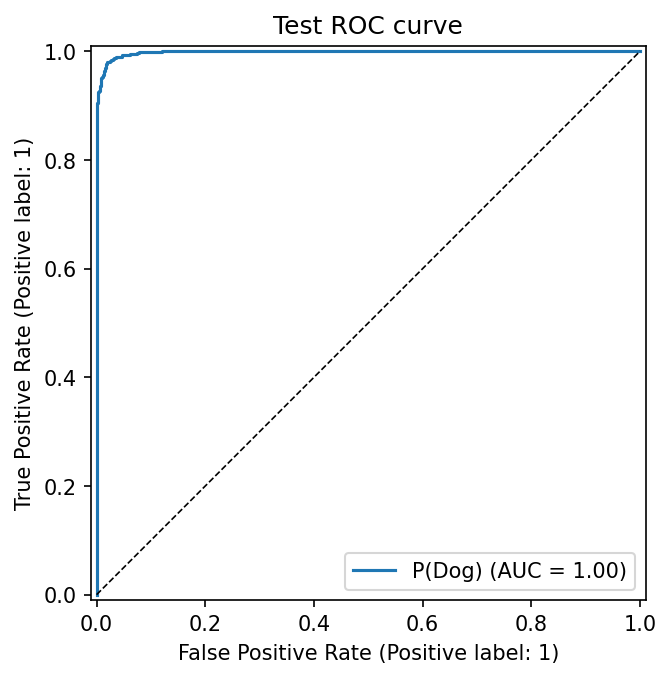

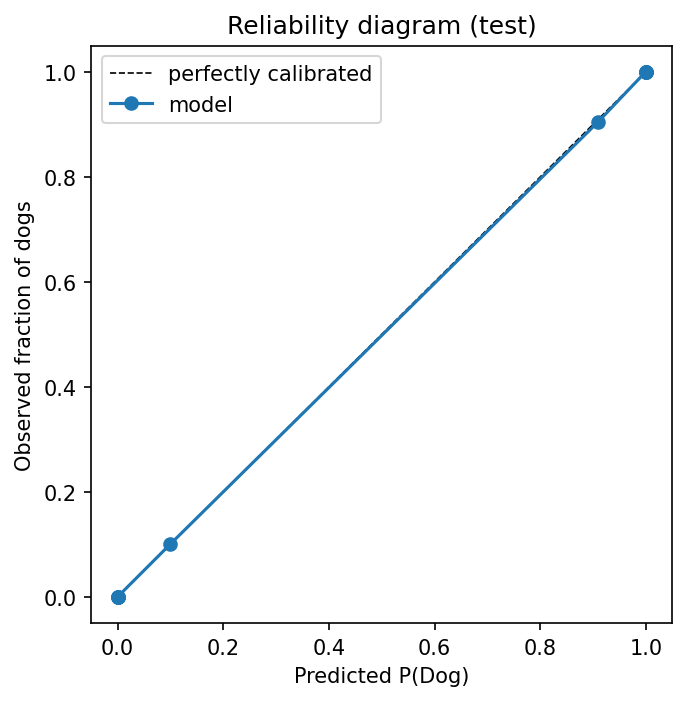

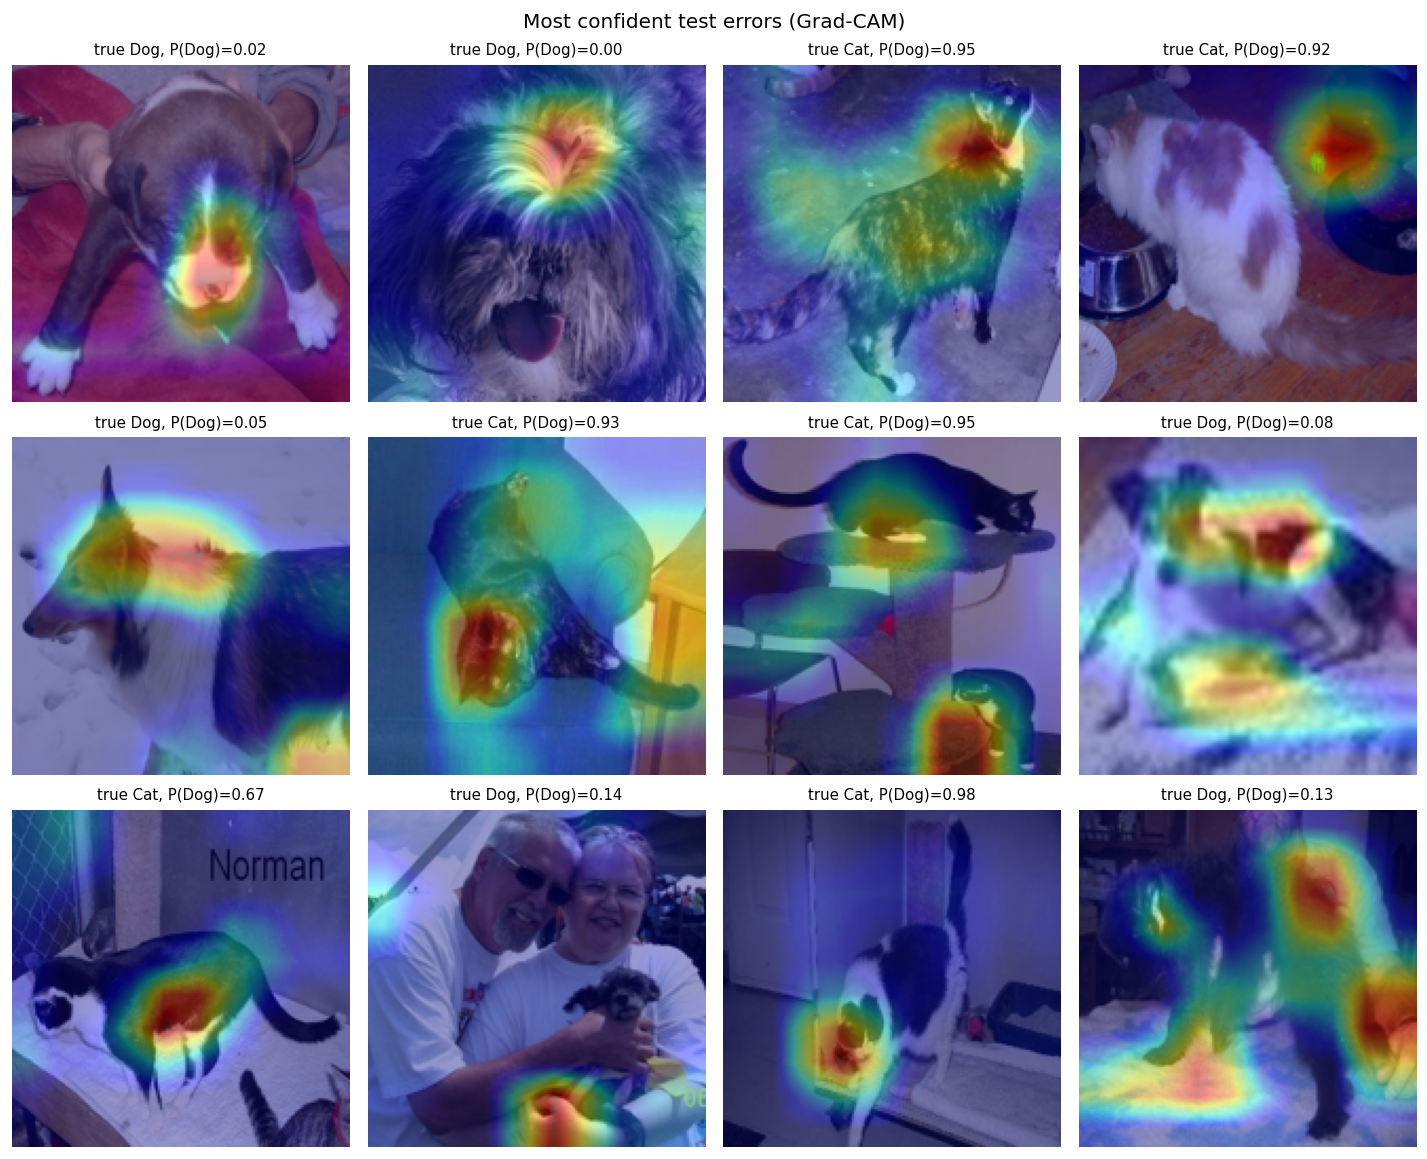

### effnet

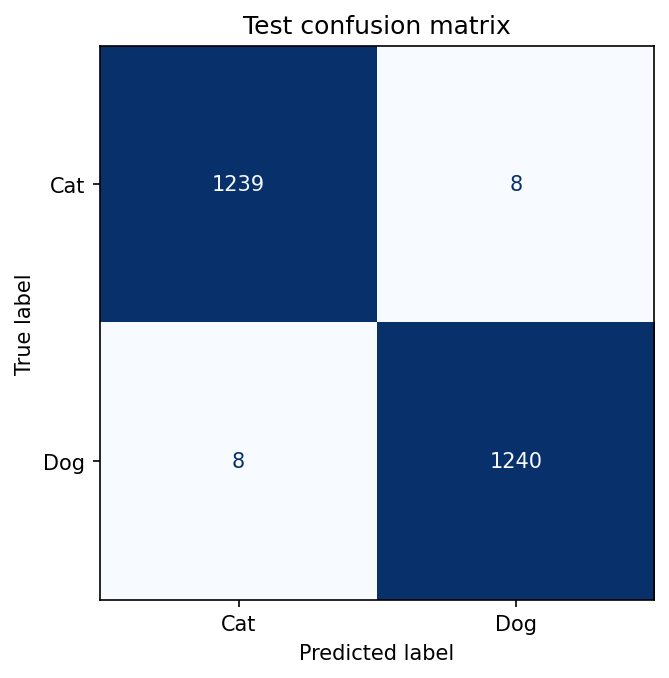

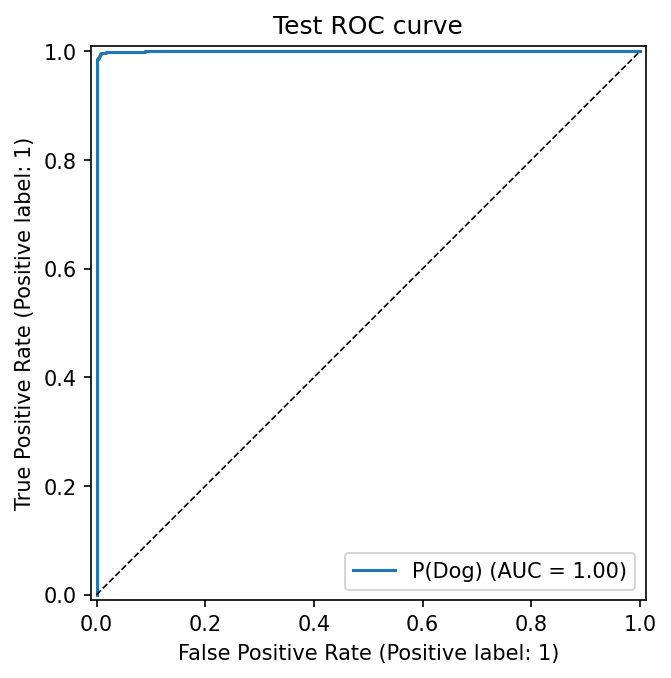

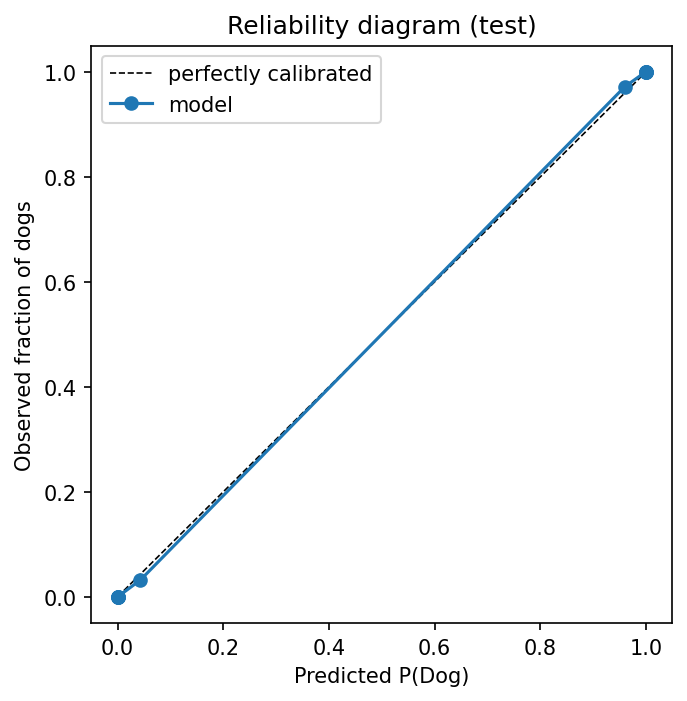

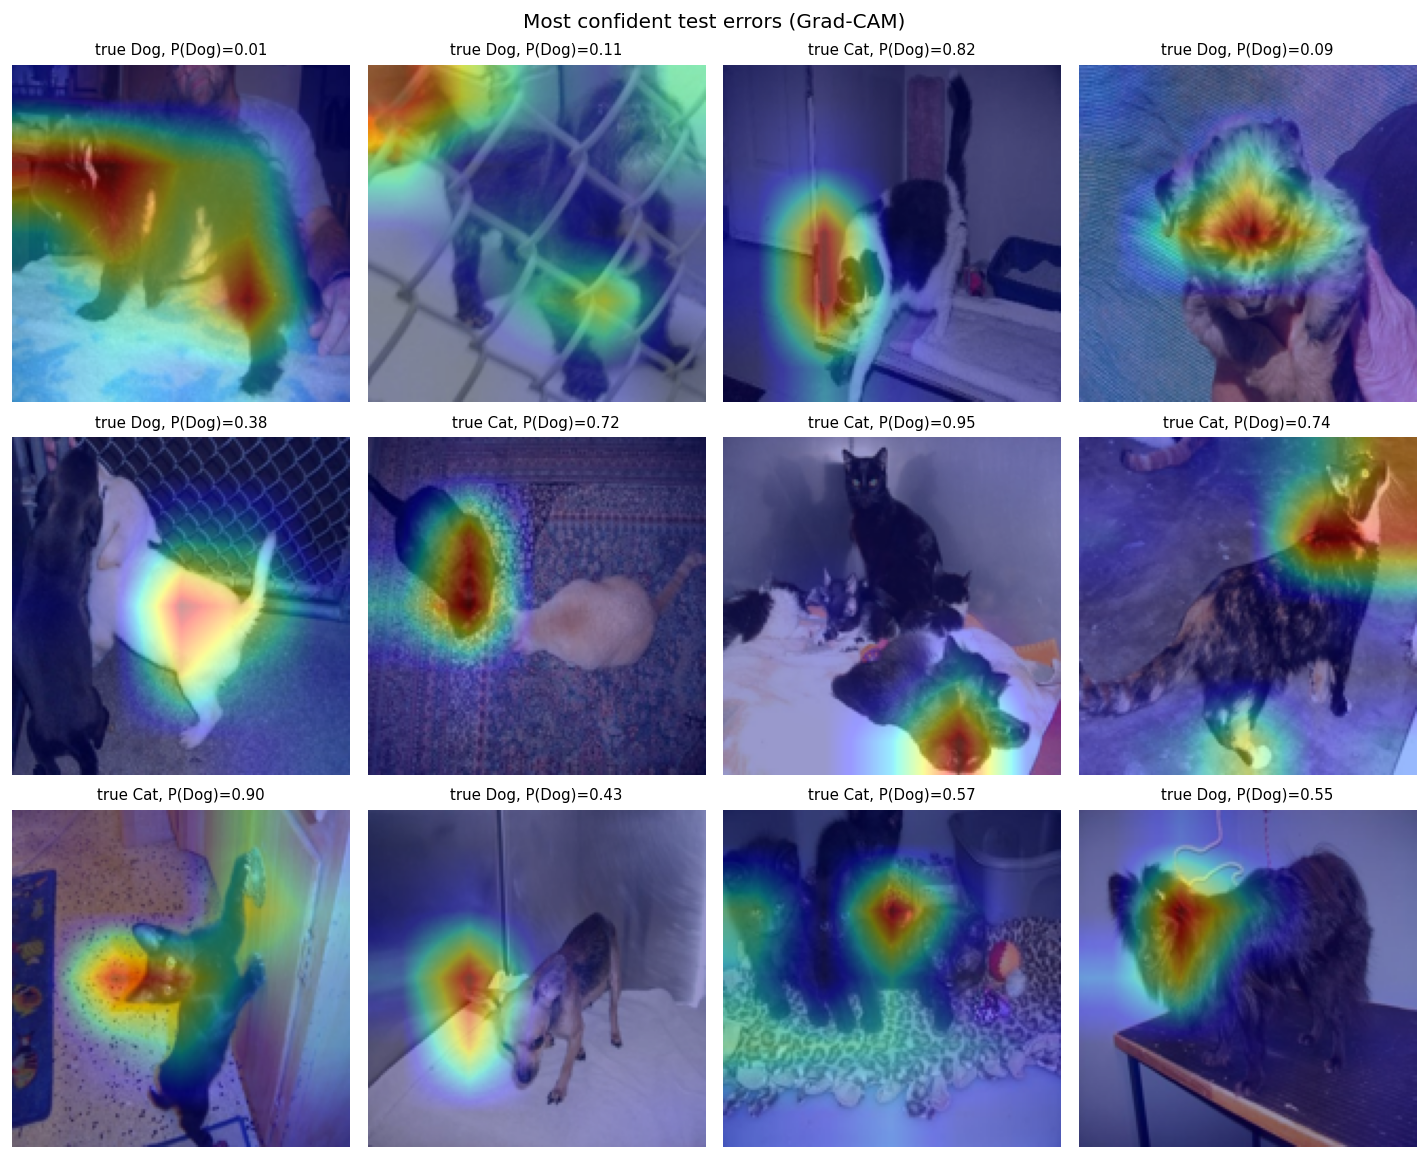

In [65]:
# 39. Plots: confusion matrix, ROC, reliability diagram, most confident errors with Grad-CAM
for name in ["ablation/3_2conv", "effnet"]:
    display(Markdown(f"### {name}"))
    for plot in ["confusion", "roc", "calibration", "errors_gradcam"]:
        path = RUNS_DIR / name / "eval" / f"{plot}.png"
        if path.exists():
            display(ShowImage(str(path), width=500))

In [ ]:
# 41.
%pip install -q gradio
import gradio as gr

demo_model = keras.models.load_model(RUNS_DIR / "effnet" / "model.keras")

def classify(image):
    img = np.asarray(image.convert("RGB").resize(IMAGE_SIZE), dtype=np.float32)
    heat, p_dog = gradcam(demo_model, img)
    return {"Dog": p_dog, "Cat": 1 - p_dog}, overlay(img, heat)

gr.Interface(fn=classify, inputs=gr.Image(type="pil"),
             outputs=[gr.Label(label="Prediction"), gr.Image(label="Grad-CAM")],
             title="Cats vs Dogs").launch(share=True)